In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import cv2
import time
from tensorflow.keras import layers, models
from tensorflow.python.keras.layers import Dense

import os

In [2]:
#Function to convert a file path of audio sound to images
dataPath = "Dataset/raw_data"
outputPath = "Dataset/preprocessed"

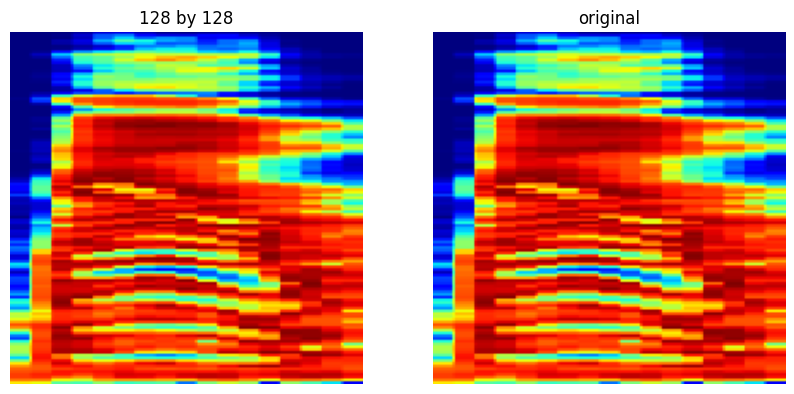

In [3]:
x = np.zeros((1,128,128))
tmp = cv2.imread("spectrogram.png",0) # 0 means gray scale

resize_tmp=cv2.resize(tmp,(128,128),interpolation=cv2.INTER_AREA) #AREA down sampling; linear slow but higher quality 
x[0]=resize_tmp

plt.figure(figsize=(10, 8))
plt.subplot(1,2,1)
plt.imshow(x[0],cmap='jet')
plt.title('128 by 128')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(resize_tmp,cmap='jet')
plt.title('original')
plt.axis('off')
plt.show()


In [5]:

"""data=os.listdir(dataPath)[2]

folder=os.path.join(dataPath,data)
for e in os.scandir(folder):
    if e.is_file():
        print(e)"""
        
        
def AudioToImage(path,output_path,targetLabel='1'):
    
    """_summary_
        This function is responsible for converting the raw audio to images 
        inputs = file path 
        targetlabel = 1 (default)
    Returns:
        _type_: image matrix(np array), labels(np array) and total number of files(int)
    """
    for index, e in  enumerate(os.listdir(path)):
        if e == targetLabel: # find target path
             tl=index
        
    #check the target path
    t=os.listdir(path)[tl]
    targetFolder = os.path.join(dataPath,t)
    #check the other file path
    x=os.listdir(path)[tl-1]
    nontargetFolder = os.path.join(dataPath,x)
    
    if os.path.exists(targetFolder) and os.path.exists(nontargetFolder):
        target_files = [e for e in os.scandir(targetFolder) if e.is_file() and e.name.lower().endswith(".wav")]
        nontarget_files = [e for e in os.scandir(nontargetFolder) if e.is_file() and e.name.lower().endswith(".wav")]
        total_files = len(target_files) + len(nontarget_files)
        
        image = np.zeros((total_files,128,128))
        label = np.zeros((total_files,))
        counter=0
        
        for e in target_files:
            y, sr = librosa.load(e)
            
            S_mel = librosa.feature.melspectrogram(
            y=y,
            sr=44100,
            n_fft=2048,        # FFT window size
            hop_length=512,     # step between windows
            n_mels=128,         # number of mel bands
            fmin=0,             # lowest frequency
            fmax=None,          # highest frequency (None = sr/2)
            power=2.0,          # 1 = energy, 2 = power
            )
            S_mel_db = librosa.power_to_db(S_mel, ref=np.max)
            
            fig, ax = plt.subplots(figsize=(10, 4))
            librosa.display.specshow(S_mel_db, sr=44100, hop_length=512,
                                    x_axis='time', y_axis='mel', ax=ax,cmap='jet')
            plt.axis('off')
            plt.tight_layout(pad=0)
            plt.savefig(f"{output_path}/spectrogram{counter}.png", dpi=300, bbox_inches='tight', pad_inches=0)
            plt.close()
            tmp=cv2.imread(f"{output_path}/spectrogram{counter}.png",0) # 0 means gray scale
            
            resize_tmp=cv2.resize(tmp,(128,128),interpolation=cv2.INTER_AREA) #AREA down sampling; linear slow but higher quality 
            image[counter]= resize_tmp
            label[counter]=1
            print(f"file done {e} {counter}")
            counter+=1
            del tmp,resize_tmp
            
        for e in nontarget_files:
            y, sr = librosa.load(e)
            #convert to spectrogram 
            S_mel = librosa.feature.melspectrogram(
            y=y,
            sr=44100,
            n_fft=2048,        # FFT window size
            hop_length=512,     # step between windows
            n_mels=128,         # number of mel bands
            fmin=0,             # lowest frequency
            fmax=None,          # highest frequency (None = sr/2)
            power=2.0,          # 1 = energy, 2 = power
            )
            S_mel_db = librosa.power_to_db(S_mel, ref=np.max)
            
            fig, ax = plt.subplots(figsize=(10, 4))
            librosa.display.specshow(S_mel_db, sr=44100, hop_length=512,
                                    x_axis='time', y_axis='mel', ax=ax,cmap='jet')
            plt.axis('off')
            plt.tight_layout(pad=0)
            plt.savefig(f"{output_path}/spectrogram{counter}.png", dpi=300, bbox_inches='tight', pad_inches=0)
            plt.close()
            tmp=cv2.imread(f"{output_path}/spectrogram{counter}.png",0) # 0 means gray scale
            # resize the image
            resize_tmp=cv2.resize(tmp,(128,128),interpolation=cv2.INTER_AREA) #AREA down sampling; linear slow but higher quality 

            image[counter]= resize_tmp
            label[counter]=0
            print(f"file done {e} {counter}")
            counter+=1
            del tmp,resize_tmp
        return image,label,total_files        
    else:
        print('here')
        return None
     
#testbench 
img,y,datapoints=AudioToImage(dataPath,outputPath)



file done <DirEntry 'help13.wav'> 0
file done <DirEntry 'help2_31.wav'> 1
file done <DirEntry 'help129.wav'> 2
file done <DirEntry 'help2_25.wav'> 3
file done <DirEntry 'help115.wav'> 4
file done <DirEntry 'help101.wav'> 5
file done <DirEntry 'help2_19.wav'> 6
file done <DirEntry 'help3_8.wav'> 7
file done <DirEntry 'help3_59.wav'> 8
file done <DirEntry 'help3_65.wav'> 9
file done <DirEntry 'help3_71.wav'> 10
file done <DirEntry 'help3_70.wav'> 11
file done <DirEntry 'help3_64.wav'> 12
file done <DirEntry 'help3_58.wav'> 13
file done <DirEntry 'help3_9.wav'> 14
file done <DirEntry 'help100.wav'> 15
file done <DirEntry 'help2_18.wav'> 16
file done <DirEntry 'help114.wav'> 17
file done <DirEntry 'help2_24.wav'> 18
file done <DirEntry 'help2_30.wav'> 19
file done <DirEntry 'help128.wav'> 20
file done <DirEntry 'help12.wav'> 21
file done <DirEntry 'help10.wav'> 22
file done <DirEntry 'help38.wav'> 23
file done <DirEntry 'help2_26.wav'> 24
file done <DirEntry 'help2_32.wav'> 25
file done <D

In [6]:
img.shape

(840, 128, 128)

Normalise the data 

In [7]:
from sklearn.preprocessing import StandardScaler

flattened_data=np.reshape(img,(datapoints,128*128))

scaler = StandardScaler()
scaler.fit(flattened_data)
input=scaler.transform(flattened_data)


Mel Spectrogram

In [8]:
tmp = input
print(tmp.shape)
print(y.shape)

(840, 16384)
(840,)


In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train,y_test = train_test_split(input,y,test_size=0.20,random_state=42)

In [10]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(672, 16384)
(168, 16384)
(672,)
(168,)


In [11]:
##RESHAPE FOR THE CNN

X_train_cnn = X_train.reshape(-1,128,128,1)
X_test_cnn = X_test.reshape(-1,128,128,1)


print(X_train_cnn.shape)
print(X_test_cnn.shape)

(672, 128, 128, 1)
(168, 128, 128, 1)


In [12]:

def buildModel(inputShape=0):
    
    start = time.time()
    if inputShape == 0:
        return print("no input given")
    else:
        model = models.Sequential()
        model.add(layers.Conv2D(32,(3,3), activation='relu',input_shape=inputShape))# 32- feature detectors 
        model.add(layers.MaxPooling2D((2,2)))
        #second layer 
        model.add(layers.Conv2D(64,(3,3),activation='relu'))
        model.add(layers.MaxPooling2D((2,2)))
        #third layer
        model.add(layers.Conv2D(128,(3,3),activation='relu'))
        
        #flatten layer 
        model.add(layers.Flatten())
        model.add(layers.Dense(64,activation='relu'))
        model.add(layers.Dense(1,activation='sigmoid'))
        
        model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
        print("> Compilation Time : ", time.time() - start)
        model.summary()
        return model

In [13]:
X_train_cnn.shape[1:]

(128, 128, 1)

> Compilation Time :  0.5300931930541992


/Users/mac/Desktop/shu_msc/Artificial Intelligence/Assignment/AI_ASSIGNMENT/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     6,422,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,515,329 (24.85 MB)

 Trainable params: 6,515,329 (24.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 197ms/step - accuracy: 0.7263 - loss: 1.8579 - val_accuracy: 0.8741 - val_loss: 0.3191
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 193ms/step - accuracy: 0.9199 - loss: 0.2548 - val_accuracy: 0.9111 - val_loss: 0.2092
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.9385 - loss: 0.1699 - val_accuracy: 0.9630 - val_loss: 0.1084
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 184ms/step - accuracy: 0.9944 - loss: 0.0297 - val_accuracy: 0.9704 - val_loss: 0.0608
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step - accuracy: 1.0000 - loss: 0.0053 - val_accuracy: 0.9852 - val_loss: 0.0339
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 215ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 0.9852 - val_loss: 0.0404
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 201ms/step - accuracy: 1.0000 - loss: 7.3607e-04 - val_accuracy: 0.9852 - val_loss: 0.0251
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 189ms/step - accuracy: 1.0000 - loss: 1.1478e-04 - val_accu

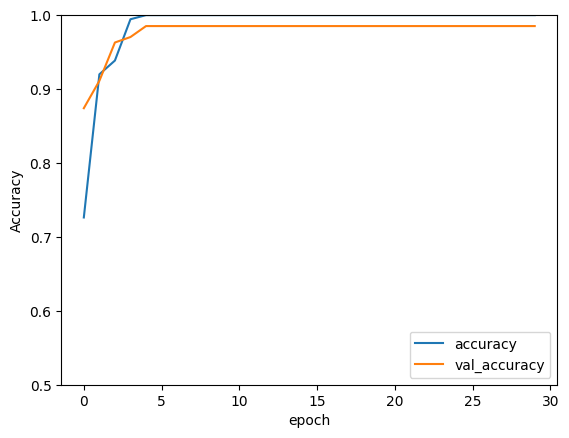

In [14]:
model = buildModel(X_train_cnn.shape[1:])
history = model.fit(X_train_cnn,y_train,epochs=30,batch_size=32,validation_split=0.2,verbose=1)

plt.plot(history.history['accuracy'],label='accuracy')
plt.plot(history.history['val_accuracy'],label='val_accuracy')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5,1])
plt.legend(loc='lower right')

test_lost, test_accuracy = model.evaluate(X_test_cnn,y_test,verbose=1)

In [15]:
print(test_lost)
print(test_accuracy)

0.052531592547893524
0.9821428656578064


In [17]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
y_pred_probs = model.predict(X_test_cnn)
y_pred = (y_pred_probs > 0.5).astype(int).flatten() 
# ============================================
# Confusion Matrix
# ============================================
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion Matrix:")
print(cm)
print(f"\nTP={tp}, TN={tn}, FP={fp}, FN={fn}")

# ============================================
#Calculate all metrics
# ============================================
accuracy    = accuracy_score(y_test, y_pred)
precision   = precision_score(y_test, y_pred)
recall      = recall_score(y_test, y_pred)         # also called sensitivity
specificity = tn / (tn + fp)
f1          = f1_score(y_test, y_pred)

print(f"\nAccuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score:    {f1:.4f}")





6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Confusion Matrix:
[[85  2]
 [ 1 80]]

TP=80, TN=85, FP=2, FN=1

Accuracy:    0.9821
Precision:   0.9756
Recall:      0.9877
Specificity: 0.9770
F1 Score:    0.9816


In [18]:
# ============================================
#Full classification report (handy summary)
# ============================================
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Not Help', 'Help']))


Classification Report:
              precision    recall  f1-score   support

    Not Help       0.99      0.98      0.98        87
        Help       0.98      0.99      0.98        81

    accuracy                           0.98       168
   macro avg       0.98      0.98      0.98       168
weighted avg       0.98      0.98      0.98       168



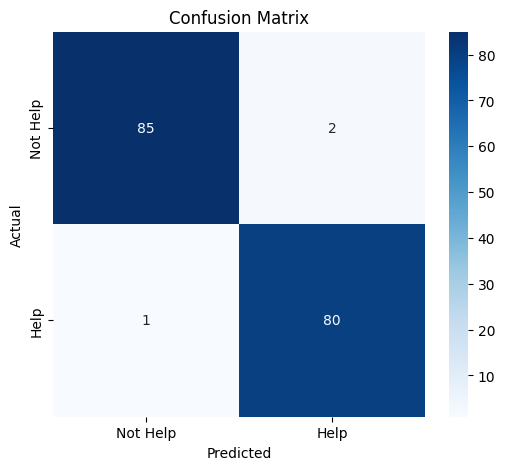

In [20]:
# ============================================
# STEP 5: Visualise the confusion matrix
# ============================================
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Help','Help'],
            yticklabels=['Not Help','Help'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()